# Policy Gradients & Actor-Critic
Topics: Policy Gradient Theorem | Score Function Trick | REINFORCE | Actor-Critic | TD Advantage

## Setup & Imports

In [1]:
!pip install tqdm gymnasium[classic-control] torch matplotlib numpy -q

In [2]:
import torch, torch.nn as nn, torch.nn.functional as F, torch.optim as optim
from torch.distributions import Categorical
import gymnasium as gym, numpy as np, matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')
from tqdm.notebook import tqdm

device = torch.device('cuda' if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else 'cpu')
print(f'Device: {device}')
torch.manual_seed(42); np.random.seed(42)

def smooth(x, w=20): return np.convolve(x, np.ones(w)/w, mode='valid')
def plot_rewards(r, title, w=20):
    plt.figure(figsize=(9,3)); plt.plot(r, alpha=0.3, label='raw')
    if len(r)>=w: plt.plot(range(w-1,len(r)), smooth(r,w), label=f'smoothed({w})')
    plt.xlabel('Episode'); plt.ylabel('Return'); plt.title(title)
    plt.legend(); plt.tight_layout(); plt.show()

print('Setup complete')

Device: mps
Setup complete


---
## 1. Policy Gradient Theorem & Score Function Trick

We want a policy $\pi_\theta(a|s)$ that maximises expected return:
$$J(\theta) = \mathbb{E}_{\tau\sim\pi_\theta}\!\left[\sum_t \gamma^t r_t\right]$$

The **Policy Gradient Theorem**:
$$\nabla_\theta J = \mathbb{E}\!\left[\sum_t \nabla_\theta \log\pi_\theta(a_t|s_t)\cdot G_t\right]$$

This follows from the **score function (log-derivative) trick**:
$$\nabla_\theta\,\mathbb{E}_{x\sim p_\theta}[f(x)] = \mathbb{E}\!\left[f(x)\cdot\nabla_\theta\log p_\theta(x)\right]$$

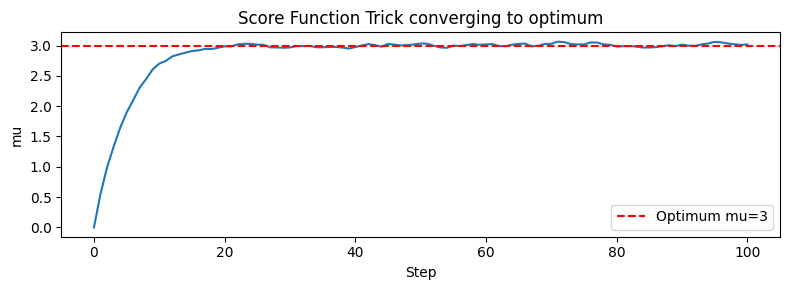

Final mu: 3.018  (target 3.0)


In [3]:
def score_grad(mu, n=500):
    x = np.random.randn(n) + mu
    f = -(x - 3)**2
    score =  x - mu 
    return np.mean(f * score)

mu, lr = 0.0, 0.1
history = [mu]
for _ in range(100):
    mu += lr * score_grad(mu)
    history.append(mu)

plt.figure(figsize=(8,3))
plt.plot(history); plt.axhline(3, color='r', ls='--', label='Optimum mu=3')
plt.xlabel('Step'); plt.ylabel('mu')
plt.title('Score Function Trick converging to optimum')
plt.legend(); plt.tight_layout(); plt.show()
print(f'Final mu: {history[-1]:.3f}  (target 3.0)')

### Baseline reduces variance

Adding a baseline $b$ leaves the gradient **unbiased** but reduces variance:
$$\nabla_\theta J \approx \mathbb{E}[(f(x)-b)\cdot\nabla_\theta\log p_\theta(x)]$$

In [4]:
def grad_variance(mu, trials=200, n=50, baseline=False):
    grads = []
    for _ in range(trials):
        x = np.random.randn(n) + mu
        f = -(x-3)**2; score = x-mu
        b = np.mean(f) if baseline else 0
        g = np.mean((f - b) * score)
        grads.append(g)
    return np.var(grads)

mu = 1.0
v0 = grad_variance(mu, baseline=False)
v1 = grad_variance(mu, baseline=True)
print(f'Variance without baseline: {v0:.2f}')
print(f'Variance with    baseline: {v1:.2f}  ({v0/v1:.1f}x reduction)')

Variance without baseline: 1.95
Variance with    baseline: 0.67  (2.9x reduction)


---
## 2. REINFORCE

REINFORCE (Williams 1992):

1. Collect full episode under $\pi_\theta$
2. Compute returns $G_t = \sum_{t'\ge t}\gamma^{t'-t}r_{t'}$
3. Update: $\theta \leftarrow \theta + \alpha\sum_t \nabla_\theta\log\pi_\theta(a_t|s_t)\cdot G_t$

Loss: $\mathcal{L} = -\sum_t \log\pi_\theta(a_t|s_t)\cdot(G_t - b)$

Training REINFORCE:   0%|          | 0/500 [00:00<?, ?it/s]

Ep  100 | Mean-100: 174.8


Ep  200 | Mean-100: 297.0


Ep  300 | Mean-100: 453.9


Ep  400 | Mean-100: 394.9


Ep  500 | Mean-100: 373.7


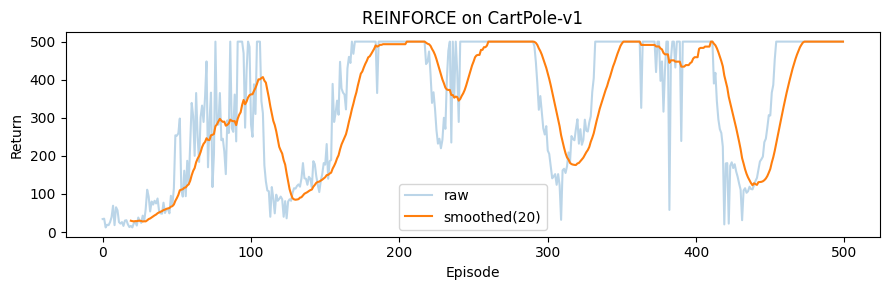

In [5]:
class PolicyNet(nn.Module):
    def __init__(self, obs_dim, n_act, h=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, h), nn.ReLU(),
            nn.Linear(h, h),       nn.ReLU(),
            nn.Linear(h, n_act)
        )
    def forward(self, x): return self.net(x)
    def act(self, s):
        s = torch.FloatTensor(s).unsqueeze(0).to(device)
        dist = Categorical(logits=self.forward(s))
        a = dist.sample()
        return a.item(), dist.log_prob(a).squeeze(0)

def compute_returns(rewards, gamma=0.99):
    G, returns = 0, []
    for r in reversed(rewards):
        G = r + gamma * G
        returns.insert(0, G)
    return returns

def reinforce_update(policy, opt, log_probs, rewards, gamma=0.99):
    returns = torch.FloatTensor(compute_returns(rewards, gamma)).to(device)
    returns = (returns - returns.mean()) / (returns.std() + 1e-8)
    loss = -(torch.stack(log_probs) * returns).mean()
    opt.zero_grad(); loss.backward(); opt.step()

def train_reinforce(n_ep=500):
    env = gym.make('CartPole-v1')
    policy = PolicyNet(4, 2).to(device)
    opt = optim.Adam(policy.parameters(), lr=3e-3)
    all_r = []
    for ep in tqdm(range(n_ep), desc='Training REINFORCE'):
        s, _ = env.reset(); lps, rs, done = [], [], False
        while not done:
            a, lp = policy.act(s)
            s, r, te, tr, _ = env.step(a); done = te or tr
            lps.append(lp); rs.append(r)
        reinforce_update(policy, opt, lps, rs)
        all_r.append(sum(rs))
        if (ep+1) % 100 == 0:
            print(f'Ep {ep+1:4d} | Mean-100: {np.mean(all_r[-100:]):.1f}')
    env.close(); return all_r, policy

reinforce_rewards, reinforce_policy = train_reinforce()
plot_rewards(reinforce_rewards, 'REINFORCE on CartPole-v1')

### REINFORCE with Learned Baseline

Subtract a state-dependent baseline $V_\phi(s_t)$: $A_t = G_t - V_\phi(s_t)$

Train two networks: policy $\pi_\theta$ with advantage updates, and value network $V_\phi$ by regressing on MC returns.

Training REINFORCE with learned baseline ...


Training REINFORCE with baseline:   0%|          | 0/500 [00:00<?, ?it/s]

Ep  100 | Mean-100: 100.2


Ep  200 | Mean-100: 409.7


Ep  300 | Mean-100: 451.2


Ep  400 | Mean-100: 490.1


Ep  500 | Mean-100: 495.2


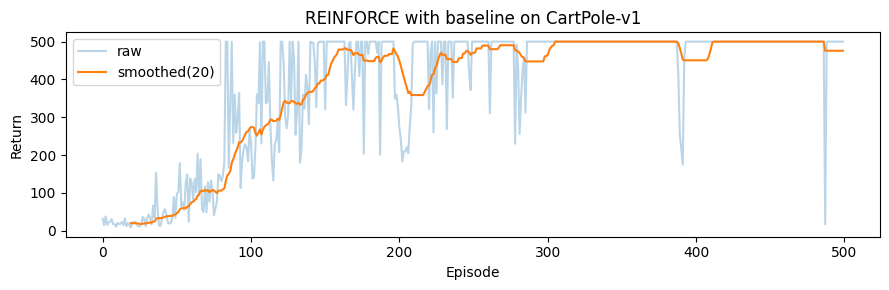

In [6]:
class ValueNet(nn.Module):
    def __init__(self, obs_dim, h=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, h), nn.ReLU(),
            nn.Linear(h, h),       nn.ReLU(),
            nn.Linear(h, 1)
        )
    def forward(self, x): return self.net(x).squeeze(-1)

def reinforce_baseline_update(policy, value_net, opt_policy, opt_value, states, log_probs, rewards, gamma=0.99):
    states  = torch.FloatTensor(np.array(states)).to(device)
    returns = torch.FloatTensor(compute_returns(rewards, gamma)).to(device)
    values = value_net(states)
    advantages = returns - values
    actor_loss = -(torch.stack(log_probs) * advantages.detach()).mean()
    critic_loss = F.mse_loss(values, returns)
    opt_policy.zero_grad()
    actor_loss.backward()
    opt_policy.step()
    opt_value.zero_grad()
    critic_loss.backward()
    opt_value.step()

def train_reinforce_with_baseline(n_ep=500):
    env = gym.make('CartPole-v1')
    policy = PolicyNet(4, 2).to(device)
    value_net = ValueNet(4).to(device)
    opt_policy = optim.Adam(policy.parameters(), lr=3e-3)
    opt_value  = optim.Adam(value_net.parameters(), lr=3e-3)
    all_r = []
    for ep in tqdm(range(n_ep), desc='Training REINFORCE with baseline'):
        s, _ = env.reset(); states, lps, rs, done = [], [], [], False
        while not done:
            a, lp = policy.act(s)
            states.append(s)
            s, r, te, tr, _ = env.step(a); done = te or tr
            lps.append(lp); rs.append(r)
        reinforce_baseline_update(policy, value_net, opt_policy, opt_value, states, lps, rs)
        all_r.append(sum(rs))
        if (ep+1) % 100 == 0:
            print(f'Ep {ep+1:4d} | Mean-100: {np.mean(all_r[-100:]):.1f}')
    env.close(); return all_r, policy, value_net

print('Training REINFORCE with learned baseline ...')
reinforce_bl_rewards, reinforce_bl_policy, reinforce_bl_value = train_reinforce_with_baseline()
plot_rewards(reinforce_bl_rewards, 'REINFORCE with baseline on CartPole-v1')

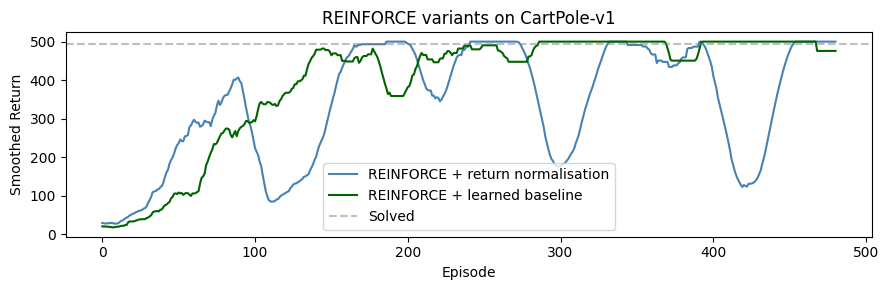

Normalised REINFORCE final 50-ep mean: 490.2
Baseline   REINFORCE final 50-ep mean: 490.3


In [7]:
plt.figure(figsize=(9,3))
plt.plot(smooth(reinforce_rewards), label='REINFORCE + return normalisation', color='steelblue')
plt.plot(smooth(reinforce_bl_rewards), label='REINFORCE + learned baseline', color='darkgreen')
plt.axhline(495, color='gray', ls='--', alpha=0.5, label='Solved')
plt.xlabel('Episode'); plt.ylabel('Smoothed Return')
plt.title('REINFORCE variants on CartPole-v1')
plt.legend(); plt.tight_layout(); plt.show()

print(f'Normalised REINFORCE final 50-ep mean: {np.mean(reinforce_rewards[-50:]):.1f}')
print(f'Baseline   REINFORCE final 50-ep mean: {np.mean(reinforce_bl_rewards[-50:]):.1f}')

---
## 3. Actor-Critic with TD Error

**Advantage:** $A^\pi(s,a) = Q^\pi(s,a) - V^\pi(s)$

**1-step TD error** as advantage estimate: $\delta_t = r_t + \gamma V(s_{t+1}) - V(s_t)$

**Actor update:** $\theta \leftarrow \theta + \alpha_\theta\,\nabla_\theta\log\pi_\theta(a_t|s_t)\cdot\delta_t$
**Critic update:** $\phi \leftarrow \phi - \alpha_\phi\,\nabla_\phi\,(\delta_t)^2$

Training Actor-Critic ...


Training Actor-Critic:   0%|          | 0/500 [00:00<?, ?it/s]

Ep  100 | Mean-100: 19.8


Ep  200 | Mean-100: 10.1


Ep  300 | Mean-100: 9.6


Ep  400 | Mean-100: 14.4


Ep  500 | Mean-100: 21.8


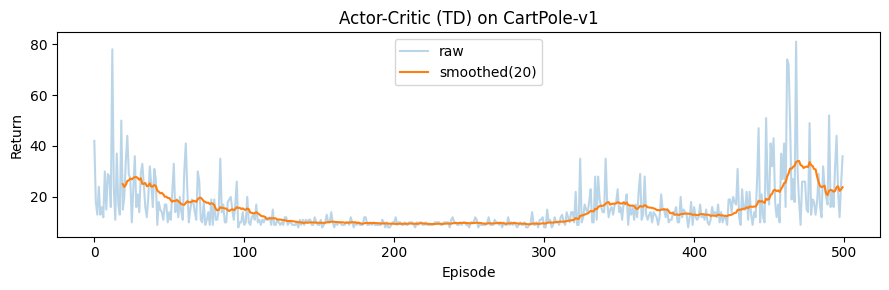

In [8]:
class ActorCritic(nn.Module):
    def __init__(self, obs_dim, n_act, h=128):
        super().__init__()
        self.shared = nn.Sequential(nn.Linear(obs_dim, h), nn.ReLU())
        self.actor  = nn.Sequential(nn.Linear(h, h), nn.ReLU(), nn.Linear(h, n_act))
        self.critic = nn.Sequential(nn.Linear(h, h), nn.ReLU(), nn.Linear(h, 1))
    def forward(self, x):
        f = self.shared(x)
        return self.actor(f), self.critic(f)
    def act(self, s):
        s = torch.FloatTensor(s).unsqueeze(0).to(device)
        logits, v = self.forward(s)
        dist = Categorical(logits=logits); a = dist.sample()
        return a.item(), dist.log_prob(a).squeeze(0), v.squeeze(-1)

def train_actor_critic(n_ep=500, gamma=0.99, ent_coef=0.01, val_coef=0.5):
    env = gym.make('CartPole-v1')
    model = ActorCritic(4, 2).to(device)
    opt = optim.Adam(model.parameters(), lr=3e-4)
    all_r = []
    for ep in tqdm(range(n_ep), desc='Training Actor-Critic'):
        s, _ = env.reset(); done = False
        a_losses, c_losses, ents = [], [], []
        ep_r = 0
        while not done:
            s_t = torch.FloatTensor(s).unsqueeze(0).to(device)
            logits, v = model(s_t)
            dist = Categorical(logits=logits); a = dist.sample()
            s2, r, te, tr, _ = env.step(a.item()); done = te or tr
            with torch.no_grad():
                _, v2 = model(torch.FloatTensor(s2).unsqueeze(0).to(device))
                v2 = torch.zeros(1,1).to(device) if done else v2
            delta = r + gamma * v2 - v
            a_losses.append(-dist.log_prob(a).squeeze(0) * delta.detach().squeeze())
            c_losses.append(delta.squeeze().pow(2))
            ents.append(dist.entropy().squeeze(0))
            s = s2; ep_r += r
        loss = torch.stack(a_losses).mean() + val_coef * torch.stack(c_losses).mean() - ent_coef * torch.stack(ents).mean()
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 0.5); opt.step()
        all_r.append(ep_r)
        if (ep+1) % 100 == 0:
            print(f'Ep {ep+1:4d} | Mean-100: {np.mean(all_r[-100:]):.1f}')
    env.close(); return all_r, model

print('Training Actor-Critic ...')
ac_rewards, ac_model = train_actor_critic()
plot_rewards(ac_rewards, 'Actor-Critic (TD) on CartPole-v1')

---
## 4. Summary & Comparison

| Algorithm | Update | Bias | Variance | Stability |
|-----------|--------|------|----------|-----------|
| REINFORCE | Monte Carlo | Low | High | Low |
| Actor-Critic (TD) | 1-step TD | High | Low | Medium |

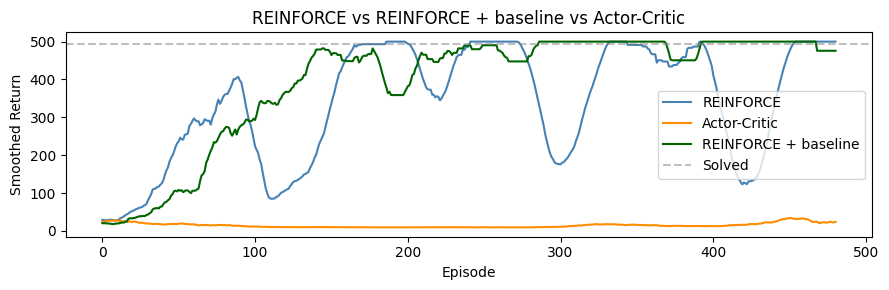

In [9]:
plt.figure(figsize=(9,3))
plt.plot(smooth(reinforce_rewards), label='REINFORCE', color='steelblue')
plt.plot(smooth(ac_rewards), label='Actor-Critic', color='darkorange')
plt.plot(smooth(reinforce_bl_rewards), label='REINFORCE + baseline', color='darkgreen')
plt.axhline(495, color='gray', ls='--', alpha=0.5, label='Solved')
plt.xlabel('Episode'); plt.ylabel('Smoothed Return')
plt.title('REINFORCE vs REINFORCE + baseline vs Actor-Critic'); plt.legend(); plt.tight_layout(); plt.show()